 <center><h1>Life Satisfaction Prediction using GDP per Capita</h1></center>


**Assignment Note**

This assignment is not intended to be a full project. It serves as a follow up to reinforce the concepts we have covered in lecture so far. More comprehensive analyses and detailed projects will be introduced as we progress further into the course.

---

## 🤔📚 Learning Objectives

- Load and visualize real-world data.
- Train and compare regression models using Scikit-Learn.
- Interpret model outputs and discuss generalization.

---

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

## Part 1: Data Exploration and Visualization (20 marks)

**Q1 (5 marks)** Load the dataset `lifesat.csv` and display the first 5 rows.

In [12]:
df = pd.read_csv("lifesat.csv")

df.head(5)

,Country,GDP per capita (USD),Life satisfaction
0,Russia,26456.387938,5.8
1,Greece,27287.083401,5.4
2,Turkey,28384.987785,5.5
3,Latvia,29932.493910,5.9
4,Hungary,31007.768407,5.6


**Q2 (5 marks)** Print basic `info` and `summary statistics`.

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country               27 non-null     object 
 1   GDP per capita (USD)  27 non-null     float64
 2   Life satisfaction     27 non-null     float64
dtypes: float64(2), object(1)
memory usage: 780.0+ bytes


In [15]:
df.describe()

,GDP per capita (USD),Life satisfaction
count,27.000000,27.000000
mean,41564.521771,6.566667
std,9631.452319,0.765607
min,26456.387938,5.400000
25%,33938.289305,5.900000
50%,41627.129269,6.800000
75%,49690.580269,7.300000
max,60235.728492,7.600000


**Q3 (10 marks)** Display a scatter plot for `GDP per capita` vs `Life Satisfaction`. Add labels, title, and discuss the observed relationship.

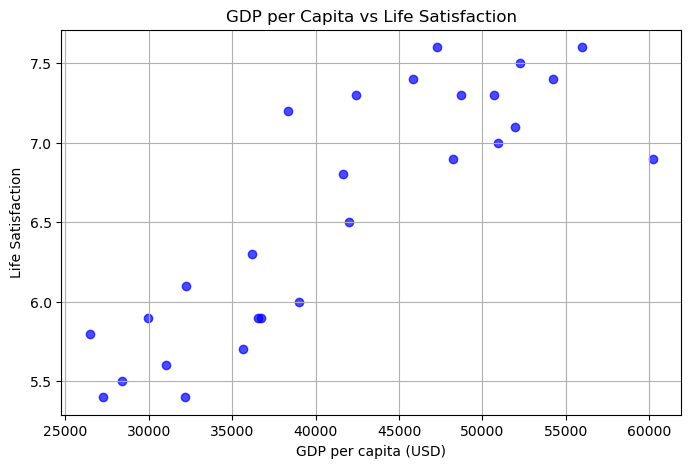

In [17]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["GDP per capita (USD)"], df["Life satisfaction"], color="blue", alpha=0.7
)
plt.title("GDP per Capita vs Life Satisfaction")
plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life Satisfaction")
plt.grid(True)
plt.show()

**Discuss the observed relationship:**

A positive linear correlation is observed between GDP per capita and life satisfaction. As GDP per capita increases, life satisfaction also increases. This demonstrates that a country's economic well-being is positively related to the standard of living of its citizens.

---

## Part 2: Linear Regression Model (30 marks)

**Q4 (5 marks)** Extract input (X) and target (y). Print their shapes.

In [28]:
X = df[["GDP per capita (USD)"]].values
y = df[["Life satisfaction"]].values

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (27, 1)
Shape of y: (27, 1)


**Q5 (10 marks)** Train a Linear Regression model & Display coefficient and intercept.

In [31]:
lin_reg = LinearRegression()
lin_reg.fit(X, y)

print(f"Coefficient (slope): {lin_reg.coef_[0][0]:.5f}")
print(f"Intercept: {lin_reg.intercept_[0]:.5f}")

Coefficient (slope): 0.00007
Intercept: 3.74905


**Q6 (10 marks)** Plot the predicted regression line from the model along with a scatter plot of the data.

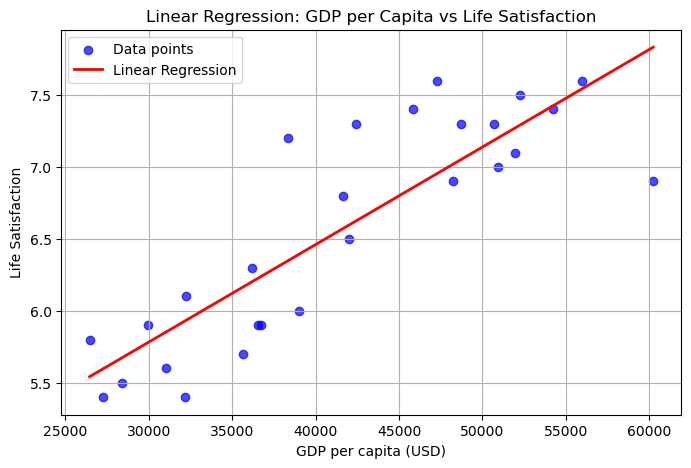

In [36]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X, y, color="blue", alpha=0.7, label="Data points"
)

X_new = np.linspace(X.min(), X.max(), 1000).reshape(-1, 1)
y_predict = lin_reg.predict(X_new)

plt.plot(X_new, y_predict, color="red", linewidth=2, label="Linear Regression")

plt.title("Linear Regression: GDP per Capita vs Life Satisfaction")
plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life Satisfaction")
plt.legend()
plt.grid(True)
plt.show()

**Q7 (5 marks)** Predict Life Satisfaction for GDP = 37,655.2 USD. Comment on result.

In [62]:
X_sample = [[37655.2]]
lin_pred = lin_reg.predict(X_sample)[0][0]

print(f"Linear Regression Prediction for GDP 37,655.2 USD: {lin_pred:.2f}")

Linear Regression Prediction for GDP 37,655.2 USD: 6.30


The linear regression model predicts a life satisfaction level of approximately 6.3 (or the exact value of the code output) for a GDP of $37,655.2. This prediction reflects the general global trend: a country with an average or above-average GDP is expected to have a correspondingly high level of life satisfaction.

---

## Part 3: K-Nearest Neighbors Regression (25 marks)

**Q8 (5 marks)** Train a KNeighborsRegressor (n_neighbors=3).

In [82]:
from sklearn.neighbors import KNeighborsRegressor

knn_model = KNeighborsRegressor(n_neighbors=3)
knn_model.fit(X, y)

KNeighborsRegressor(n_neighbors=3)

**Q9 (10 marks)**

- Predict Life Satisfaction for GDP = 37,655.2 USD
- and compare with Linear Regression.

In [95]:
X_sample = [[37655.2]]

knn_pred = knn_model.predict(X_sample).item()
lin_pred = lin_reg.predict(X_sample).item()

print(f"KNN (n_neighbors=3) prediction: {knn_pred:.2f}")
print(f"Linear Regression prediction: {lin_pred:.2f}")

KNN (n_neighbors=3) prediction: 6.33
Linear Regression prediction: 6.30


**Q10 (10 marks)**

- Use n_neighbors 1, 3, 5, and 10 and print the predicted values of life satisfaction in Q10.
- Plot the results using a line plot.

n_neighbors =  1 -> Predicted Life Satisfaction: 7.2000
n_neighbors =  3 -> Predicted Life Satisfaction: 6.3333
n_neighbors =  5 -> Predicted Life Satisfaction: 6.2600
n_neighbors = 10 -> Predicted Life Satisfaction: 6.3700


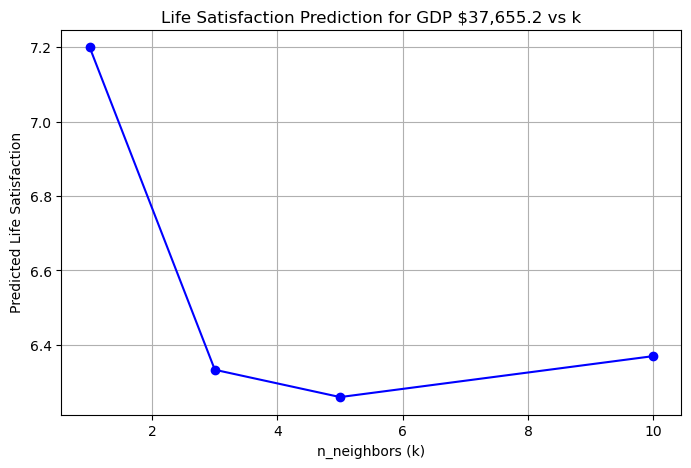

In [101]:
import matplotlib.pyplot as plt

neighbors_list = [1, 3, 5, 10]
pred_list = []
X_sample = [[37655.2]]

for k in neighbors_list:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X, y)
    pred = knn.predict(X_sample).item()
    pred_list.append(pred)
    print(f"n_neighbors = {k:2d} -> Predicted Life Satisfaction: {pred:.4f}")

# Plot n vs pred_list
plt.figure(figsize=(8, 5))
plt.plot(neighbors_list, pred_list, marker='o', linestyle='-', color='b')
plt.xlabel('n_neighbors (k)')
plt.ylabel('Predicted Life Satisfaction')
plt.title('Life Satisfaction Prediction for GDP $37,655.2 vs k')
plt.grid(True)
plt.show()